# Region and age of civilian award winners (1954–2021)

**Team 007 | An Analysis of India's Civilian and Military Honours**

**Question (Q1).** How have civilian award winners (Bharat Ratna and the three Padma awards) changed in **region** and **age** between the first four decades (1954–1993) and the later period (1994–2021)?

**Data.** `..datasets/cleaned_datasets/national_awards_cleaned.csv`: 4,875 award records (name, award, field, state or country, year, year of birth, age at award) for Bharat Ratna, Padma Vibhushan, Padma Bhushan and Padma Shri, 1954–2021. Age at award is known for only 1,650 of them (see section 3).

**Hypotheses**

| | Statement |
|---|---|
| **H0** | Region and age distribution have remained the same. |
| **H1** | Region changed, age unchanged. |
| **H2** | Region unchanged, age changed. |
| **H3** | Both region and age changed. |

**Layout of the notebook**

1. Setup: load the data, tag every winner with a region and a period
2. Region: tables and graphs
3. Age: tables and graphs
4. Hypothesis tests (region, then age)
5. Verdict on H0–H3
6. Conclusion
7. Limitations

**Methods.** Every test in section 4 comes from Sheldon Ross, *Introduction to Probability and Statistics for Engineers and Scientists*, **chapter 8 (hypothesis testing)**, and no other test is used. The exact sections are named where each test is introduced.

## 1. Setup

### 1.1 Settings and libraries

All the settings that someone might want to change are in this one cell: the file name, the four awards, the two periods and the significance level α. `scipy.stats` is used only to look up tail probabilities (normal, t, F and hypergeometric) for the Chapter 8 tests that are written out by hand in section 4.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm, t, f, hypergeom   # tail probabilities only

sns.set_theme(style="whitegrid")

DATA_FILE = "../datasets/cleaned_datasets/national_awards_cleaned.csv"
AWARDS = ["Bharat Ratna", "Padma Vibhushan", "Padma Bhushan", "Padma Shri"]
SCOPES = ["All awards"] + AWARDS            # "All awards" pools the four awards
PERIODS = ["1954-1993", "1994-2021"]        # period 1 (early) and period 2 (later)
ALPHA = 0.05                                # significance level used for every test

### 1.2 Regions

Each state or country in the data is mapped to one of seven regions: six Indian regions (North, South, East, West, Central, North-East) and **Foreign** for every place outside India. The mapping is a plain dictionary so it is easy to read and to change. Any state not in the dictionary is counted as Foreign, so the cell prints the most common Foreign places to check that no Indian state was missed.

In [2]:
REGIONS = {
    "North": ["Delhi", "Punjab", "Haryana", "Chandigarh", "Himachal Pradesh",
              "Jammu and Kashmir", "Ladakh", "Uttarakhand", "Uttar Pradesh", "Rajasthan"],
    "South": ["Tamil Nadu", "Karnataka", "Kerala", "Telangana", "Andhra Pradesh",
              "Puducherry", "Lakshadweep"],
    "East": ["West Bengal", "Odisha", "Bihar", "Jharkhand", "Andaman and Nicobar"],
    "West": ["Maharashtra", "Gujarat", "Goa", "Daman and Diu"],
    "Central": ["Madhya Pradesh", "Chhattisgarh"],
    "North-East": ["Assam", "Manipur", "Mizoram", "Meghalaya", "Sikkim",
                   "Nagaland", "Arunachal Pradesh", "Tripura"],
}
REGION_ORDER = list(REGIONS) + ["Foreign"]
state_to_region = {state: region for region, states in REGIONS.items() for state in states}

### 1.3 Load the data and tag each winner

Two columns are added to every row:

- **Region**: from the dictionary above; places that are not in it become `Foreign`.
- **Period**: `1954-1993` if the award year is 1993 or earlier, otherwise `1994-2021`.

`aged` is the subset of winners whose age at award is known. It is used for everything about age.

In [3]:
df = pd.read_csv(DATA_FILE)
for col in ["Award", "State/Country"]:
    df[col] = df[col].str.strip()

df["Region"] = df["State/Country"].map(state_to_region).fillna("Foreign")
df["Period"] = np.where(df["Year"] <= 1993, PERIODS[0], PERIODS[1])
df = df[df["Award"].isin(AWARDS)]

aged = df.dropna(subset=["AgeAtAward"])      # winners with a known age

print(f"{len(df)} winners in total, {len(aged)} with a known age at award\n")
print("Most common places labelled Foreign (check that no Indian state is here):")
print(df.loc[df["Region"] == "Foreign", "State/Country"].value_counts().head(8).to_string())

print("\nAll winners, by award and period:")
display(pd.crosstab(df["Award"], df["Period"], margins=True).reindex(AWARDS + ["All"]))
print("Winners with a known age, by award and period:")
display(pd.crosstab(aged["Award"], aged["Period"], margins=True).reindex(AWARDS + ["All"]))

4875 winners in total, 3561 with a known age at award

Most common places labelled Foreign (check that no Indian state is here):
State/Country
United States of America    117
United Kingdom               43
France                       15
Russia                       13
Japan                        13
Germany                       9
United Arab Emirates          7
Canada                        6

All winners, by award and period:


Period,1954-1993,1994-2021,All
Award,,,
Bharat Ratna,29,19,48
Padma Vibhushan,141,180,321
Padma Bhushan,714,567,1281
Padma Shri,1463,1762,3225
All,2347,2528,4875


Winners with a known age, by award and period:


Period,1954-1993,1994-2021,All
Award,,,
Bharat Ratna,22,19,41
Padma Vibhushan,109,152,261
Padma Bhushan,502,451,953
Padma Shri,772,1534,2306
All,1405,2156,3561


**Reading the tables.** The two periods are similar in size for region (2,347 winners in 1954–1993 and 2,528 in 1994–2021). For age they are very different: age is known for 1,392 winners in the first period but for only 258 in the second. Bharat Ratna has only 48 winners (29 and 19), so any test on it alone has little power. Section 3 shows when the known ages are concentrated.

## 2. Region of award winners

### 2.1 Counts and percentages by region

For each award, and for all four awards pooled, this cell counts the winners from each region in each period, and converts the counts to percentages of that period's winners. Both tables are saved as CSV files (`region_counts_by_period.csv`, `region_percentages_by_period.csv`). The preview shows the pooled table with the change in share in percentage points (pp).

In [4]:
def region_counts_for(data):
    table = pd.crosstab(data["Region"], data["Period"])
    return table.reindex(index=REGION_ORDER, columns=PERIODS, fill_value=0)

counts = {s: region_counts_for(df if s == "All awards" else df[df["Award"] == s]) for s in SCOPES}
shares = {s: counts[s] / counts[s].sum() * 100 for s in SCOPES}      # % of that period's winners

pd.concat(counts, names=["Award", "Region"]).to_csv("region_counts_by_period.csv")
pd.concat(shares, names=["Award", "Region"]).round(2).to_csv("region_percentages_by_period.csv")

pooled = pd.DataFrame({
    "winners_1954-1993": counts["All awards"][PERIODS[0]],
    "winners_1994-2021": counts["All awards"][PERIODS[1]],
    "share_1954-1993_%": shares["All awards"][PERIODS[0]],
    "share_1994-2021_%": shares["All awards"][PERIODS[1]],
})
pooled["change_pp"] = pooled["share_1994-2021_%"] - pooled["share_1954-1993_%"]
display(pooled.round(1))

,winners_1954-1993,winners_1994-2021,share_1954-1993_%,share_1994-2021_%,change_pp
Region,,,,,
North,826,807,35.2,31.9,-3.3
South,507,612,21.6,24.2,2.6
East,300,201,12.8,8.0,-4.8
West,518,460,22.1,18.2,-3.9
Central,48,67,2.0,2.7,0.6
North-East,73,151,3.1,6.0,2.9
Foreign,75,230,3.2,9.1,5.9


### 2.2 Graphs

1. **Regional share of winners** in both periods (all awards pooled).
2. **Biggest gainers and losers** among individual states and countries.

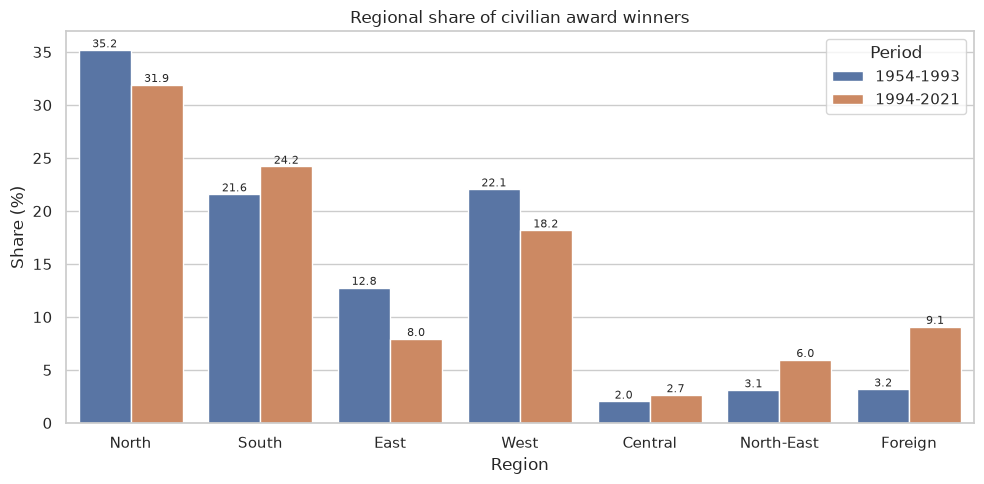

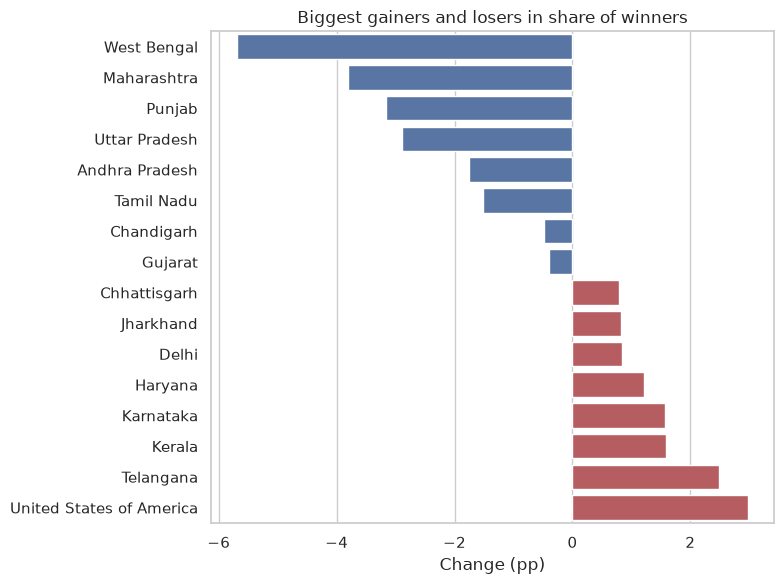

In [5]:
# Graph 1: regional share, both periods, all awards pooled
plot_data = shares["All awards"].reset_index().melt(id_vars="Region", var_name="Period", value_name="Share (%)")
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=plot_data, x="Region", y="Share (%)", hue="Period")
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f", fontsize=8)
plt.title("Regional share of civilian award winners")
plt.tight_layout()
plt.show()


# Graph 2: biggest gainers and losers among states / countries
place_share = pd.crosstab(df["State/Country"], df["Period"], normalize="columns") * 100
movers = (place_share[PERIODS[1]] - place_share[PERIODS[0]]).sort_values()
movers = pd.concat([movers.head(8), movers.tail(8)]).rename("Change (pp)").reset_index()
plt.figure(figsize=(8, 6))
sns.barplot(data=movers, y="State/Country", x="Change (pp)", hue=movers["Change (pp)"] > 0,
            palette={True: "#C44E52", False: "#4C72B0"}, legend=False)
plt.title("Biggest gainers and losers in share of winners")
plt.ylabel("")
plt.tight_layout()
plt.show()

**Reading the graphs**

- **Graph 1 (pooled).** The East fell from 12.8% to 8.0% and the West from 22.1% to 18.2%. The North fell from 35.2% to 31.9%. Foreign winners rose from 3.2% to 9.1%, the North-East from 3.1% to 6.0%, and the South from 21.6% to 24.2%. Central stays small (2.0% to 2.7%).
- **Graph 2 (states and countries).** The biggest loser is West Bengal (−5.7 pp), followed by Maharashtra (−3.8), Punjab (−3.2) and Uttar Pradesh (−2.9). The biggest gainer is the United States (+3.0 pp), followed by Telangana (+2.5), Kerala (+1.6) and Karnataka (+1.6).
- These are descriptive. Whether the changes are bigger than chance is tested in section 4.1.

## 3. Age of award winners

### 3.1 Age summary

Only winners with a known birth year have an age, so everything in this section uses `aged`. For each award (and all awards pooled) and each period, the cell gives the number of winners, the mean, the standard deviation and the three quartiles. In this analysis, age at award is defined as the age of the awardee at the time of the felicitation, computed as the award year minus the year of birth. For posthumous awards, the age is computed in the same way: it is the age the awardee would have reached in the award year, not the age at death. The table is saved as `age_summary_by_period.csv`.

In [6]:
rows = []
for scope in SCOPES:
    data = aged if scope == "All awards" else aged[aged["Award"] == scope]
    for period in PERIODS:
        ages = data.loc[data["Period"] == period, "AgeAtAward"]
        rows.append({"Award": scope, "Period": period, "count": len(ages), "mean": ages.mean(),
                     "std": ages.std(), "q1": ages.quantile(0.25), "median": ages.median(),
                     "q3": ages.quantile(0.75)})

age_summary = pd.DataFrame(rows).round(1)
age_summary.to_csv("age_summary_by_period.csv", index=False)
display(age_summary)

,Award,Period,count,mean,std,q1,median,q3
0,All awards,1954-1993,1405,59.6,13.2,52.0,60.0,68.0
1,All awards,1994-2021,2156,68.0,14.9,60.0,69.0,78.0
2,Bharat Ratna,1954-1993,22,77.5,11.5,70.0,74.5,82.5
3,Bharat Ratna,1994-2021,19,87.6,22.2,79.5,87.0,95.0
4,Padma Vibhushan,1954-1993,109,68.0,12.4,60.0,66.0,76.0
5,Padma Vibhushan,1994-2021,152,77.6,11.7,70.0,78.0,86.0
6,Padma Bhushan,1954-1993,502,63.0,11.4,56.0,62.0,70.0
7,Padma Bhushan,1994-2021,451,72.2,13.3,64.0,73.0,82.0
8,Padma Shri,1954-1993,772,55.7,12.9,48.0,55.0,64.0
9,Padma Shri,1994-2021,1534,65.6,14.7,58.0,66.0,76.0


### 3.2 Graphs

1. **Age by award type**: box plots for the two periods.
2. **Age bands**: the share of winners in each age band, per period (all awards pooled).

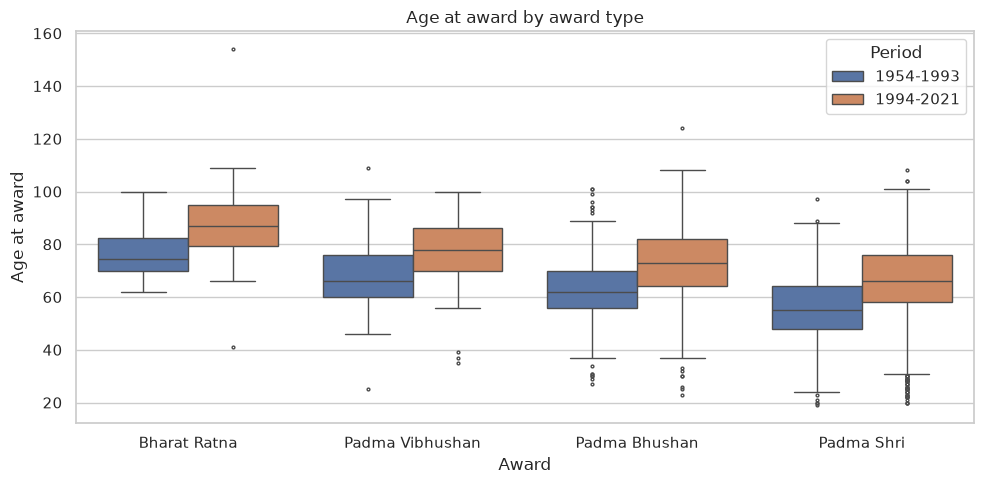

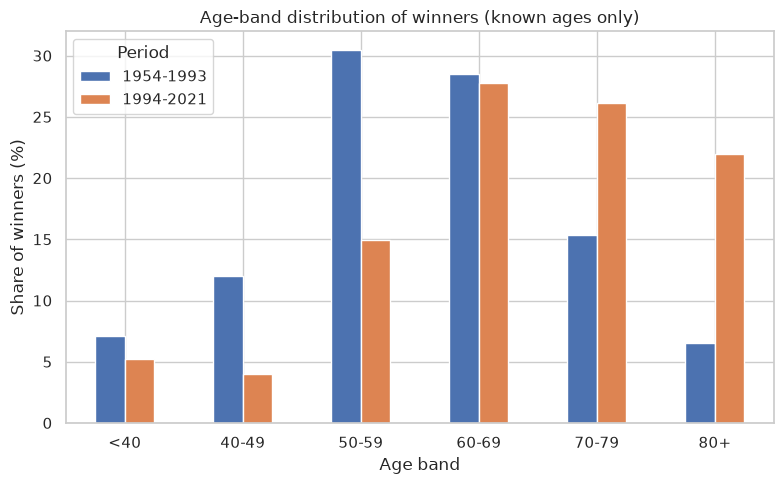

In [7]:
# Graph 1: age at award by award type
plt.figure(figsize=(10, 5))
sns.boxplot(data=aged, x="Award", y="AgeAtAward", hue="Period", order=AWARDS, hue_order=PERIODS, fliersize=2)
plt.title("Age at award by award type")
plt.ylabel("Age at award")
plt.tight_layout()
plt.show()

# Graph 2: share of winners in each age band
bands = pd.cut(aged["AgeAtAward"], [0, 40, 50, 60, 70, 80, 200], right=False,
               labels=["<40", "40-49", "50-59", "60-69", "70-79", "80+"])
band_share = (pd.crosstab(bands, aged["Period"], normalize="columns") * 100)[PERIODS]
band_share.plot(kind="bar", figsize=(8, 5), rot=0)
plt.title("Age-band distribution of winners (known ages only)")
plt.xlabel("Age band")
plt.ylabel("Share of winners (%)")
plt.tight_layout()
plt.show()


**Reading the table and graphs**

- **Summary table.** Pooled, the mean age at award was 59.6 in 1954–1993 and 67.8 in 1994–2021 (medians 60 and 68). Every award shows a higher mean in the later period: Bharat Ratna 77.5 → 84.6, Padma Vibhushan 67.6 → 75.9, Padma Bhushan 63.1 → 70.5, Padma Shri 55.7 → 61.8. The spread is also larger later (standard deviation 13.2 → 15.4).
- **Graph 1.** The later box sits higher for every award. Padma Shri winners are the youngest and Bharat Ratna winners the oldest in both periods.
- **Graph 2.** Winners aged 80 or more rose from 6.5% to 23.6%, while winners under 50 fell from 19.0% to 9.0%.

## 4. Hypothesis tests

**Why two kinds of tests.** Region is a category, so the natural question is "what proportion of winners comes from region j, and is that proportion different in the two periods?". That is a test of two Bernoulli proportions (Ross, section 8.6). Age is a number, so the question is "is the mean age different?". That is a test of two means (Ross, section 8.4).

**Decision rule.** α = 0.05 for every test. A test rejects its H0 when its p-value is below α. Each test has H0: *no change* against a two-sided alternative, because a change can go either way.

### 4.1 Region: two Bernoulli populations (Ross, section 8.6)

**Model.** For one region j, every winner in a period is a Bernoulli trial: success means the winner is from region j. Period 1 has n₁ winners of whom x₁ are from j, so x₁ is Binomial(n₁, p₁). Period 2 has n₂ winners and x₂ from j, Binomial(n₂, p₂). Here p is the **share of winners from that region**, not a probability of being chosen. For each region:

- **H0:** p₁ = p₂ (the region's share is the same in both periods).
- **H1:** p₁ ≠ p₂.

**Which test.** Ross gives two tests for this:

- **Fisher–Irwin exact test (section 8.6.1).** Given x₁ + x₂ = k, X₁ has a hypergeometric distribution when H0 is true, and the p-value is 2·min( P{X ≤ x₁}, P{X ≥ x₁} ). It needs no approximation, so it is used when counts are small.
- **Normal approximation for large n₁ and n₂ (Ross, problem 63 of chapter 8).** With p̂₁ = x₁/n₁, p̂₂ = x₂/n₂ and pooled p̂ = (x₁ + x₂)/(n₁ + n₂),

  z₀ = (p̂₂ − p̂₁) / √( p̂(1 − p̂)(1/n₁ + 1/n₂) )

  is approximately standard normal under H0, and the two-sided p-value is 2·P(Z ≥ |z₀|).

The z-test is used when n₁p̂, n₁(1 − p̂), n₂p̂ and n₂(1 − p̂) are all at least 5, and the Fisher–Irwin test otherwise. The `test_used` column says which one was used.

**What counts as "region changed".** There is one test per region (seven per scope). The region distribution is said to have changed if **at least one region's share differs significantly** between the periods. A region distribution that is unchanged would have all seven shares unchanged. The headline result is the **All awards** scope.

In [8]:
def fisher_irwin(x1, n1, x2, n2):
    # Ross 8.6.1: given x1 + x2 = k, X1 is hypergeometric under H0
    X = hypergeom(M=n1 + n2, n=n1, N=x1 + x2)
    return min(1.0, 2 * min(X.cdf(x1), X.sf(x1 - 1)))

def two_proportion_test(x1, n1, x2, n2):
    # Two-sided test of H0: p1 = p2. Returns the test used, z0 (if z-test) and the p-value.
    p1, p2 = x1 / n1, x2 / n2
    pooled = (x1 + x2) / (n1 + n2)
    counts_large_enough = min(n1 * pooled, n1 * (1 - pooled), n2 * pooled, n2 * (1 - pooled)) >= 5
    if counts_large_enough:
        z0 = (p2 - p1) / np.sqrt(pooled * (1 - pooled) * (1 / n1 + 1 / n2))
        return "z", z0, 2 * norm.sf(abs(z0))
    return "Fisher-Irwin", np.nan, fisher_irwin(x1, n1, x2, n2)

rows = []
for scope in SCOPES:
    n1, n2 = counts[scope][PERIODS[0]].sum(), counts[scope][PERIODS[1]].sum()
    for region in REGION_ORDER:
        x1, x2 = counts[scope].loc[region, PERIODS[0]], counts[scope].loc[region, PERIODS[1]]
        test, z0, p = two_proportion_test(x1, n1, x2, n2)
        rows.append({"Scope": scope, "Region": region, "x1": x1, "n1": n1, "x2": x2, "n2": n2,
                     "share_1_%": 100 * x1 / n1, "share_2_%": 100 * x2 / n2,
                     "change_pp": 100 * (x2 / n2 - x1 / n1),
                     "test_used": test, "z0": z0, "p_value": p, "significant": p < ALPHA})

region_tests = pd.DataFrame(rows)
region_tests.to_csv("region_test.csv", index=False)

print("All awards pooled (the headline result):")
display(region_tests[region_tests["Scope"] == "All awards"].drop(columns="Scope").round(4))

print("Regions with a significant change in share, per scope:")
display(region_tests.groupby("Scope")["significant"].sum().reindex(SCOPES).to_frame("regions_significant_of_7"))

All awards pooled (the headline result):


,Region,x1,n1,x2,n2,share_1_%,share_2_%,change_pp,test_used,z0,p_value,significant
0,North,826,2347,807,2528,35.1939,31.9225,-3.2714,z,-2.4181,0.0156,True
1,South,507,2347,612,2528,21.6020,24.2089,2.6068,z,2.1625,0.0306,True
2,East,300,2347,201,2528,12.7823,7.9509,-4.8313,z,-5.5506,0.0000,True
3,West,518,2347,460,2528,22.0707,18.1962,-3.8745,z,-3.3753,0.0007,True
4,Central,48,2347,67,2528,2.0452,2.6503,0.6052,z,1.3911,0.1642,False
5,North-East,73,2347,151,2528,3.1104,5.9731,2.8627,z,4.7700,0.0000,True
6,Foreign,75,2347,230,2528,3.1956,9.0981,5.9025,z,8.5028,0.0000,True


Regions with a significant change in share, per scope:


,regions_significant_of_7
Scope,
All awards,6
Bharat Ratna,0
Padma Vibhushan,2
Padma Bhushan,2
Padma Shri,7


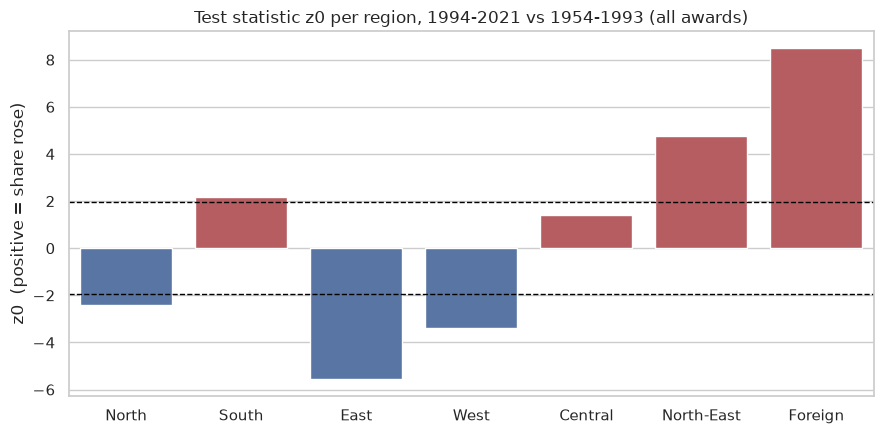

In [9]:
# z0 for each region (pooled): bars beyond the dashed lines are significant at 5% (critical value 1.96)
pooled_tests = region_tests[region_tests["Scope"] == "All awards"]
critical = norm.isf(ALPHA / 2)

plt.figure(figsize=(9, 4.5))
sns.barplot(data=pooled_tests, x="Region", y="z0", hue=pooled_tests["z0"] > 0,
            palette={True: "#C44E52", False: "#4C72B0"}, legend=False)
plt.axhline(critical, color="black", linestyle="--", linewidth=1)
plt.axhline(-critical, color="black", linestyle="--", linewidth=1)
plt.title("Test statistic z0 per region, 1994-2021 vs 1954-1993 (all awards)")
plt.ylabel("z0  (positive = share rose)")
plt.xlabel("")
plt.tight_layout()
plt.show()

**Reading section 4.1 (all awards pooled, n₁ = 2,347 and n₂ = 2,528)**

| region | share 1954–93 | share 1994–2021 | change (pp) | z₀ | p-value | result at α = 0.05 |
|---|---|---|---|---|---|---|
| North | 35.2% | 31.9% | −3.3 | −2.42 | 0.016 | decreased |
| South | 21.6% | 24.2% | +2.6 | 2.16 | 0.031 | increased |
| East | 12.8% | 8.0% | −4.8 | −5.55 | < 0.0001 | decreased |
| West | 22.1% | 18.2% | −3.9 | −3.38 | 0.0007 | decreased |
| Central | 2.0% | 2.7% | +0.6 | 1.39 | 0.164 | not significant |
| North-East | 3.1% | 6.0% | +2.9 | 4.77 | < 0.0001 | increased |
| Foreign | 3.2% | 9.1% | +5.9 | 8.50 | < 0.0001 | increased |

- Six of the seven regions changed their share significantly, so H0 (no change in region) is rejected for the pooled data. Only Central, which is tiny, did not change.
- The four clearest changes (East, West, North-East, Foreign) have p-values below 0.001, so they do not depend on the choice of 5% as the cut-off.
- **By award.** Padma Shri changes in all seven regions. Padma Bhushan and Padma Vibhushan each change in two regions (East down, Foreign up). Bharat Ratna shows no significant change in any region, but with 29 and 19 winners the test has very little power, so this means "not enough data", not "no change". The Fisher–Irwin test was used for most of its regions because the counts are small.
- The graph shows the same thing: the Foreign, North-East and South bars are above +1.96, East, West and North are below −1.96, and Central lies between the dashed lines.

### 4.2 Age: two normal populations (Ross, sections 8.4 and 8.5.1)

**Model.** Let X₁, …, Xₙ be the ages of winners with known age in period 1 (mean μₓ, variance σₓ²) and Y₁, …, Yₘ the ages in period 2 (mean μᵧ, variance σᵧ²). For each scope:

- **H0:** μₓ = μᵧ (mean age is the same in both periods).
- **H1:** μₓ ≠ μᵧ.

**Step A. Are the variances equal? (Ross, section 8.5.1).** H0: σₓ² = σᵧ² against H1: σₓ² ≠ σᵧ². Under H0, Sₓ²/Sᵧ² has an F distribution with n − 1 and m − 1 degrees of freedom, and the p-value is 2·min( P{F < v}, 1 − P{F < v} ) where v is the observed ratio. The answer decides which test of the means to use.

**Step B. Compare the means.**

- **Equal variances (section 8.4.2).** The pooled estimator is S²ₚ = ((n − 1)Sₓ² + (m − 1)Sᵧ²)/(n + m − 2), and

  T = (X̄ − Ȳ) / √( S²ₚ (1/n + 1/m) )

  has a t distribution with n + m − 2 degrees of freedom under H0. The p-value is 2·P(T_{n+m−2} ≥ |T|).
- **Unequal variances, large samples (section 8.4.3).** Ross notes that the exact unequal-variance problem has no completely satisfactory solution, but when n and m are both large,

  Z = (X̄ − Ȳ) / √( Sₓ²/n + Sᵧ²/m )

  is approximately standard normal under H0, and the p-value is 2·P(Z ≥ |Z|). "Large" is taken as at least 30 winners in each period.

**Rule used.** If the variance test (step A) does not reject at α, use the pooled t-test (8.4.2). If it rejects, use the large-sample test (8.4.3). The `caution` column is `True` when either period has fewer than 30 winners, because then the normality assumption matters and the result should be read carefully.

Ross's tests assume the ages are roughly normal. The ages here are somewhat right-skewed with a few very large values, but with hundreds of winners per period the sample means are close to normal, so the pooled scopes are on safe ground. The headline result is again the **All awards** row.

In [10]:
rows = []
for scope in SCOPES:
    data = aged if scope == "All awards" else aged[aged["Award"] == scope]
    x = data.loc[data["Period"] == PERIODS[0], "AgeAtAward"]
    y = data.loc[data["Period"] == PERIODS[1], "AgeAtAward"]
    n, m = len(x), len(y)
    diff = y.mean() - x.mean()

    # Step A: F-test for equal variances (Ross 8.5.1)
    v = x.var() / y.var()
    p_var = 2 * min(f.cdf(v, n - 1, m - 1), f.sf(v, n - 1, m - 1))

    # Step B: test of the means
    if p_var >= ALPHA:                                   # equal variances: pooled t-test (8.4.2)
        pooled_var = ((n - 1) * x.var() + (m - 1) * y.var()) / (n + m - 2)
        stat = diff / np.sqrt(pooled_var * (1 / n + 1 / m))
        p_value = 2 * t.sf(abs(stat), n + m - 2)
        test = "pooled t (8.4.2)"
    else:                                                # unequal variances: large-sample z (8.4.3)
        stat = diff / np.sqrt(x.var() / n + y.var() / m)
        p_value = 2 * norm.sf(abs(stat))
        test = "large-sample z (8.4.3)"

    rows.append({"Scope": scope, "n_1": n, "n_2": m, "mean_1": x.mean(), "mean_2": y.mean(),
                 "diff_years": diff, "sd_1": x.std(), "sd_2": y.std(), "p_equal_var": p_var,
                 "test_used": test, "statistic": stat, "p_value": p_value,
                 "significant": p_value < ALPHA, "caution": min(n, m) < 30})

age_tests = pd.DataFrame(rows)
age_tests.to_csv("age_test.csv", index=False)
display(age_tests.round(4))

,Scope,n_1,n_2,mean_1,mean_2,diff_years,sd_1,sd_2,p_equal_var,test_used,statistic,p_value,significant,caution
0,All awards,1405,2156,59.6157,68.0065,8.3908,13.2373,14.9016,0.0000,large-sample z (8.4.3),17.5838,0.0000,True,False
1,Bharat Ratna,22,19,77.5455,87.5789,10.0335,11.5335,22.2294,0.0049,large-sample z (8.4.3),1.7722,0.0764,False,True
2,Padma Vibhushan,109,152,68.0183,77.5724,9.5540,12.4194,11.6651,0.4753,pooled t (8.4.2),6.3511,0.0000,True,False
3,Padma Bhushan,502,451,63.0438,72.2328,9.1890,11.4300,13.2853,0.0010,large-sample z (8.4.3),11.3835,0.0000,True,False
4,Padma Shri,772,1534,55.6891,65.5737,9.8845,12.9121,14.7018,0.0000,large-sample z (8.4.3),16.5465,0.0000,True,False


**Reading section 4.2**

| scope | n (early / later) | mean age (early → later) | variance test p | test used | statistic | p-value | result |
|---|---|---|---|---|---|---|---|
| **All awards** | 1,392 / 258 | 59.6 → 67.8 (+8.2) | 0.0009 | large-sample z | 8.03 | ≈ 1e-15 | increased |
| Bharat Ratna | 22 / 11 | 77.5 → 84.6 (+7.1) | 0.49 | pooled t | 1.57 | 0.128 | not significant (small n) |
| Padma Vibhushan | 108 / 42 | 67.6 → 75.9 (+8.3) | 0.87 | pooled t | 3.88 | 0.0002 | increased |
| Padma Bhushan | 501 / 82 | 63.1 → 70.5 (+7.4) | 0.003 | large-sample z | 4.41 | 0.00001 | increased |
| Padma Shri | 761 / 123 | 55.7 → 61.8 (+6.1) | 0.09 | pooled t | 4.74 | 0.000002 | increased |

- For the pooled data the variances are different (p = 0.0009), so the large-sample test is used. The mean age rose by about 8 years and H0 (no change in age) is rejected with a very small p-value. With the pooled t-test instead, the conclusion is the same (T ≈ 8.9).
- The rise is about 6 to 8 years in every award, and is significant in three of the four. Bharat Ratna also rose by about 7 years but is not significant, because only 11 winners in the later period have a known age (`caution = True`).
- The test says the mean age of winners with a known age differs between the periods. It does not say why, and the later-period sample is small and concentrated in 1998–2001 (section 7).

## 5. Verdict on the hypotheses

Using the **All awards** results: region changed if at least one region's share differs significantly (section 4.1), and age changed if the test of the mean ages rejects H0 (section 4.2). Each hypothesis states what it claims about region and age, and it is supported only if both claims match the test results.

In [11]:
region_changed = region_tests.loc[region_tests["Scope"] == "All awards", "significant"].any()
age_changed = bool(age_tests.loc[age_tests["Scope"] == "All awards", "significant"].iloc[0])

claims = {"H0": (False, False), "H1": (True, False), "H2": (False, True), "H3": (True, True)}
verdict = pd.DataFrame([{"Hypothesis": h, "Claims region changed": r, "Claims age changed": a,
                         "Supported": (r, a) == (region_changed, age_changed)}
                        for h, (r, a) in claims.items()])

n_sig = int(region_tests.loc[region_tests["Scope"] == "All awards", "significant"].sum())
age_p = age_tests.loc[age_tests["Scope"] == "All awards", "p_value"].iloc[0]
print(f"Region: {n_sig} of 7 regions changed significantly -> {'changed' if region_changed else 'no significant change'}")
print(f"Age:    p = {age_p:.2g} -> {'changed' if age_changed else 'no significant change'}\n")
display(verdict)

Region: 6 of 7 regions changed significantly -> changed
Age:    p = 3.3e-69 -> changed



,Hypothesis,Claims region changed,Claims age changed,Supported
0,H0,False,False,False
1,H1,True,False,False
2,H2,False,True,False
3,H3,True,True,True


## 6. Conclusion

**Region.** The regional mix of winners changed significantly. Six of the seven regions have a significantly different share in 1994–2021 (pooled data, Ross section 8.6 tests).

1. The East lost share in every award (4.8 pp pooled; −15.4 pp in Bharat Ratna and −9.4 pp in Padma Bhushan). West Bengal is the biggest single loser (−5.7 pp), followed by Maharashtra, Punjab and Uttar Pradesh.
2. Foreign winners rose in every award (3.2% → 9.1% pooled), with the United States the largest single gainer (+3.0 pp).
3. The North-East (3.1% → 6.0%) and the South (21.6% → 24.2%) also gained, led by Telangana, Kerala and Karnataka.
4. Bharat Ratna and Padma Vibhushan have few winners, so their per-award region results are less reliable.

**Age.** Winners with a known age were older in 1994–2021: the mean rose from 59.6 to 67.8 years (about 8 years; p ≈ 1e-15 from the large-sample test of Ross section 8.4.3). The rise of 6 to 8 years appears in all four awards and is significant in Padma Vibhushan, Padma Bhushan and Padma Shri.

**Hypotheses.** H0, H1 and H2 are rejected. The data support **H3**: both the region and the age distribution of winners changed. The region result rests on all 4,875 winners. The age result rests on the 1,650 winners with a known age, and for the later period mostly on 1998–2001, so it is the weaker of the two.

## 7. Limitations

1. **Age is missing for two thirds of winners, and unevenly.** Age is known for 1,392 of 2,347 winners in 1954–1993 (59%) but for only 258 of 2,528 in 1994–2021 (10%), and 248 of those 258 are from 1998–2001. The age comparison is therefore really "1954–1993 winners against mostly 1998–2001 winners", and it may not describe 1994–2021 as a whole. If winners with a known birth year differ from the rest (for example, better-known and older people), the result is also biased.
2. **Years with no records.** The data has no winners for 1978, 1979, 1993, 1994, 1995 and 1996, so the first period is effectively 1954–1992 (except 1978–79) and the later period starts in 1997.
3. **Share of winners is not a selection probability.** Without the pool of eligible people from each region, the tests describe who was awarded, not whether a region's chance of being chosen changed.
4. **Independence.** Ross's tests treat winners as independent trials. Lists are decided in yearly batches and one person can receive several awards (the pooled scope counts that person each time), so this is a simplification.
5. **Normality for age.** The tests of means assume roughly normal ages. Ages are right-skewed with some extreme values (the oldest is 124, which may be a data error). With hundreds of winners the means are close to normal, but the Bharat Ratna result (22 and 11 winners) is not reliable, which is why it is flagged with `caution`.
6. **Many tests, no correction.** Seven region tests are run per scope (35 in all), each at α = 0.05, so a few significant results at the 5% level could be false positives. The headline conclusions rest on the pooled results with p < 0.001 (East, West, North-East, Foreign, and age), not on borderline ones such as North (p = 0.016) or South (p = 0.031).
7. **Non-significant does not mean unchanged.** Small groups (Bharat Ratna, Central region) have low power.
8. **Region grouping.** The six Indian regions come from the dictionary in section 1.2. Moving a state (for example Delhi) changes the shares. State labels are as given in the data; for example Telangana (formed in 2014) appears as a state, but it and Andhra Pradesh are both in the South, so the region results are not affected.
9. **Fixed split.** The 1993/1994 cut is the one given in the question; other cut points were not tried.